<a href="https://colab.research.google.com/github/sancarg/Machine_Learning/blob/master/Fraud_Detection/fraud_detection_logistic_regression_with_deepcheck.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WELLCOME

Welcome to "***Fraud Detection Project***".

One of the challenges in this project is the absence of domain knowledge. So without knowing what the column names are, you will only be interested in their values. The other one is the class frequencies of the target variable are quite imbalanced.

You will implement ***Logistic Regression algorithms** and Unbalanced Data Techniques . Also visualize performances of the models using **Seaborn, Matplotlib** and ***Yellowbrick*** in a variety of ways.

Data drift and model drirft are key consepts about ML and MLOPS, you can monitor and check your data and models with plenty of ways and tools. ***Deepchecks*** is one of them and the leading tool for testing and for validating your machine learning models and data, and it enables doing so with minimal effort. In this project, you will apply ***Data Integrity, Train-Test Validation, and Model Evaluation*** checks.
Deepchecks Intruduction : https://youtu.be/7ELdizoi6BU

Before diving into the project, please take a look at the Determines and Tasks.

- **NOTE:** This tutorial assumes that you already know the basics of coding in Python and are familiar with model deployement (Streamlit) as well as the theory behind algorithms*


# Determines
The datasets contains transactions made by credit cards in September 2013 by european cardholders. This dataset presents transactions that occurred in two days, where it has **492 frauds** out of **284,807** transactions. The dataset is **highly unbalanced**, the positive class (frauds) account for 0.172% of all transactions.

**Feature Information:**

**Time**: This feature is contains the seconds elapsed between each transaction and the first transaction in the dataset.

**Amount**:  This feature is the transaction Amount, can be used for example-dependant cost-senstive learning.

**Class**: This feature is the target variable and it takes value 1 in case of fraud and 0 otherwise.

---

The aim of this project is to predict whether a credit card transaction is fraudulent. Of course, this is not easy to do.
First of all, you need to analyze and recognize your data well in order to draw your roadmap and choose the correct arguments you will use. Accordingly, you can examine the frequency distributions of variables. You can observe variable correlations and want to explore multicollinearity. You can display the distribution of the target variable's classes over other variables.
Also, it is useful to take missing values and outliers.

After these procedures, you can move on to the model building stage by doing the basic data pre-processing you are familiar with.

Start with Logistic Regression and evaluate model performance. You will apply the Unbalanced Data Techniques used to increase the performance. Next, observe their effects.

Then, you will use four different algorithms in the model building phase.


# Tasks

### Model Building

- Logistic Regression


### Import Modules, Load Data & Data Review

In [ ]:
pip install shap

In [ ]:
pip install scikeras

In [ ]:
pip install imbalanced-learn==0.12.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.3/258.3 kB 7.9 MB/s eta 0:00:00
  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.14.2
    Uninstalling imbalanced-learn-0.14.2:
      Successfully uninstalled imbalanced-learn-0.14.2


In [ ]:
pip install deepchecks

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 128.9 MB/s eta 0:00:00


In [ ]:
pip install streamlit

In [ ]:
# main libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import plotly
import plotly.express as px
import plotly.figure_factory as ff
import shap
import tensorflow as tf

#To display the plots
# %matplotlib inline

# Figure&Display options
plt.rcParams["figure.figsize"] = (10,6)
sns.set_style("whitegrid", {'axes.grid' : False})
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
from plotly.figure_factory import create_distplot
import plotly.graph_objects as go

# to get rid of the warnings
import warnings
warnings.filterwarnings("ignore")
warnings.warn("this will not show")

# libraries for scaling
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OrdinalEncoder

# libraries for model selection
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold, cross_val_predict,StratifiedKFold

# libraries for regression/classification
from sklearn.linear_model import LogisticRegression

# sklearn library for performance metrics
from sklearn.metrics import log_loss, recall_score, accuracy_score, precision_score, f1_score
from sklearn.metrics import make_scorer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.metrics import average_precision_score,precision_recall_curve, roc_curve, roc_auc_score

from yellowbrick.classifier import PrecisionRecallCurve

# library for sampling methods
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE

# misceallenous libraries
import matplotlib.gridspec as gridspec # to do the grid of plots
from sklearn.pipeline import Pipeline
from termcolor import colored
from scipy.stats import iqr
from sklearn.utils import class_weight

# loading joblib
import joblib
import os

In [ ]:
from sklearn.metrics._scorer import _SCORERS

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Loading The Preprocessed Data Splits

In [ ]:
data = joblib.load('/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/preprocessed_data_splits.joblib')
X_train, X_test, y_train, y_test = data['X_train'], data['X_test'], data['y_train'], data['y_test']

In [ ]:
#X_train, X_test, y_train, y_test = joblib.load('/content/drive/MyDrive/ML_Capstone_Project/3. Fraud Detection Analysis Project/preprocessed_data.joblib').values()

## 3.Model Building

It was previously stated that you need to make class prediction with three different algorithms. As in this case, different approaches are required to obtain better performance on unbalanced data.

This dataset is severely **unbalanced** (most of the transactions are non-fraud). So the algorithms are much more likely to classify new observations to the majority class and high accuracy won't tell us anything. To address the problem of imbalanced dataset, we can use undersampling and oversampling or class weight and optimum threshold techniques.

***Note***:

- *If you are going to use the cross validation method to be more sure of the performance of your model for unbalanced data, you should make sure that the class distributions in the iterations are equal. This prevents folds from being skewed towards certain classes, leading to a more accurate evaluation of the model's performance on unseen data. For this case, you should use **[StratifiedKFold](https://www.analyseup.com/python-machine-learning/stratified-kfold.html)** instead of regular cross validation method.*

## 3.1 Logistic Regression

### 3.1.1 Logistic Regression With Default Parameters

In [ ]:
def eval_metric(model, X_train, y_train, X_test, y_test):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    print("TEST REPORT")
    print(classification_report(y_test, y_pred_test))
    confusion_matrix_test = confusion_matrix(y_test, y_pred_test)
    ConfusionMatrixDisplay(confusion_matrix_test).plot();
    print("\n"*3, "-*"*30)
    print("TRAIN REPORT")
    print(classification_report(y_train, y_pred_train))
    confusion_matrix_train = confusion_matrix(y_train, y_pred_train)
    ConfusionMatrixDisplay(confusion_matrix_train).plot()
    plt.show()

In [ ]:
log_vanila = LogisticRegression(random_state=0)

In [ ]:
log_vanila.fit(X_train, y_train)

LogisticRegression(random_state=0)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.63      0.71        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.89      0.62      0.73       394

    accuracy                           1.00    227845
   macro avg       0.94      0.81      0.87    227845
weighted avg       1.00      1.00      1.00    227845



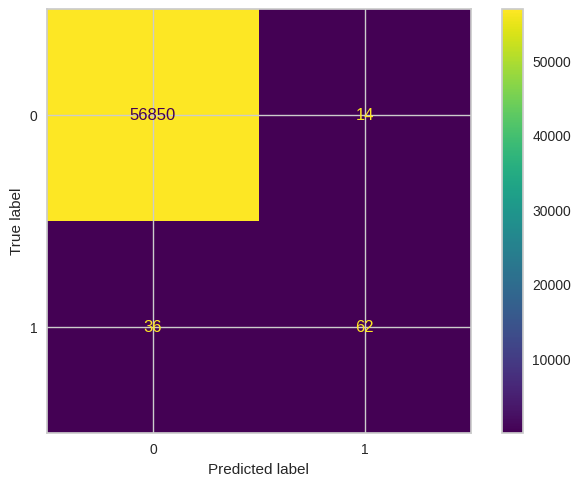

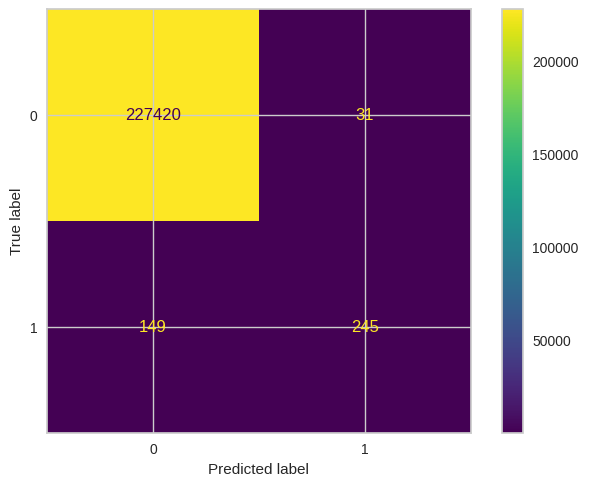

In [ ]:
eval_metric(log_vanila, X_train, y_train, X_test, y_test)

### 3.1.2 Logistic Regression With Class_Weight

In [ ]:
log_model = LogisticRegression(class_weight={1:20,0:1},max_iter=10000, random_state=0)

In [ ]:
log_model.fit(X_train, y_train)

LogisticRegression(class_weight={0: 1, 1: 20}, max_iter=10000, random_state=0)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.63      0.86      0.73        98

    accuracy                           1.00     56962
   macro avg       0.82      0.93      0.86     56962
weighted avg       1.00      1.00      1.00     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.69      0.82      0.75       394

    accuracy                           1.00    227845
   macro avg       0.85      0.91      0.88    227845
weighted avg       1.00      1.00      1.00    227845



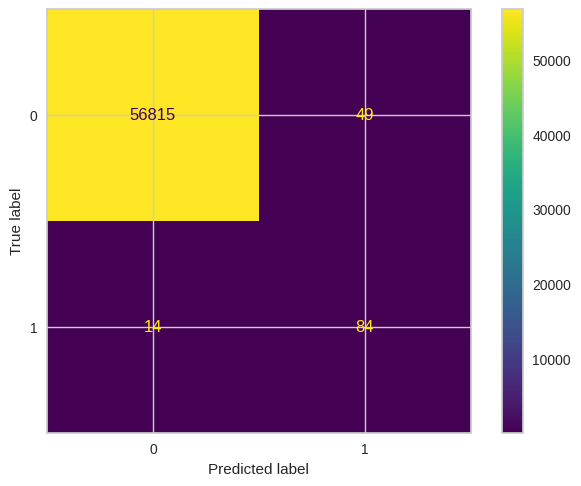

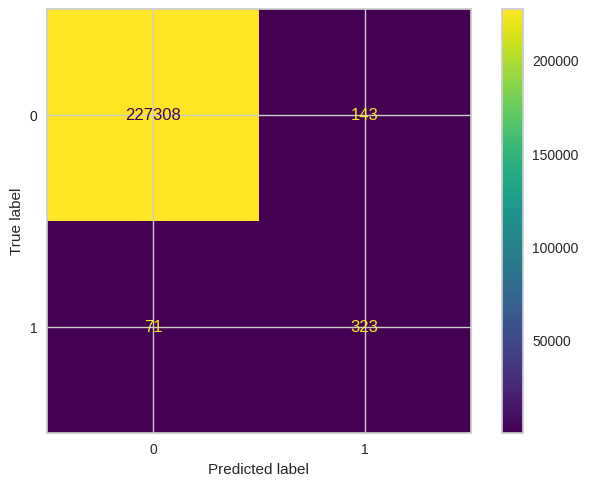

In [ ]:
eval_metric(log_model, X_train, y_train, X_test, y_test)

#### 3.1.2.1 Logistic Model Cross Validation ( StratifiedKFold)

In [ ]:
skf = StratifiedKFold(n_splits=10,shuffle=True, random_state=0)

In [ ]:
model = log_model
scores = cross_validate(model, X_train, y_train, scoring = ['precision','recall','f1'], cv = skf, return_train_score=True)
df_scores = pd.DataFrame(scores, index = range(1, 11))
df_scores

,fit_time,score_time,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
1,0.644,0.019,0.627,0.709,0.821,0.831,0.711,0.765
2,0.617,0.018,0.729,0.690,0.875,0.819,0.795,0.749
3,0.642,0.018,0.738,0.702,0.775,0.831,0.756,0.761
4,0.685,0.018,0.755,0.689,0.925,0.808,0.831,0.744
5,0.665,0.019,0.686,0.697,0.875,0.814,0.769,0.751
6,0.617,0.020,0.744,0.695,0.821,0.820,0.780,0.752
7,0.629,0.018,0.682,0.704,0.769,0.831,0.723,0.762
8,0.641,0.036,0.738,0.696,0.795,0.820,0.765,0.753
9,0.622,0.021,0.596,0.711,0.718,0.831,0.651,0.766
10,0.634,0.018,0.689,0.702,0.795,0.823,0.738,0.757


In [ ]:
df_scores.mean()[2:]

,0
test_precision,0.698
train_precision,0.700
test_recall,0.817
train_recall,0.823
test_f1,0.752
train_f1,0.756


### 3.1.3 Logistic Model GridsearchCV

In [ ]:
model = log_model
penalty = ['l1', 'l2']
C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
solver = ['liblinear', 'lbfgs',"saga"]
param_grid = {"penalty" : penalty,
             "C" : C,
             "solver" : solver}
log_grid_model = GridSearchCV(model, param_grid = param_grid, scoring="recall", cv=skf, n_jobs=-1)

In [ ]:
log_grid_model.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=LogisticRegression(class_weight={0: 1, 1: 20},
                                          max_iter=10000, random_state=0),
             n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'lbfgs', 'saga']},
             scoring='recall')

In [ ]:
log_grid_model.best_params_

{'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}

In [ ]:
log_grid_model.best_score_

np.float64(0.8193589743589744)

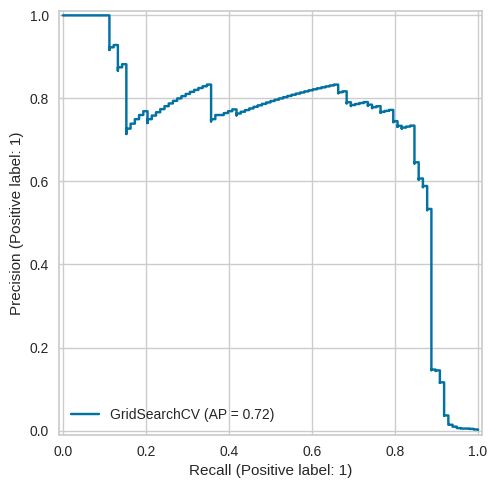

In [ ]:
PrecisionRecallDisplay.from_estimator(log_grid_model, X_test, y_test);

In [ ]:
y_pred_proba = log_grid_model.predict_proba(X_test)[:, 1]
average_precision = average_precision_score(y_test, y_pred_proba)
average_precision

np.float64(0.7235894789176436)

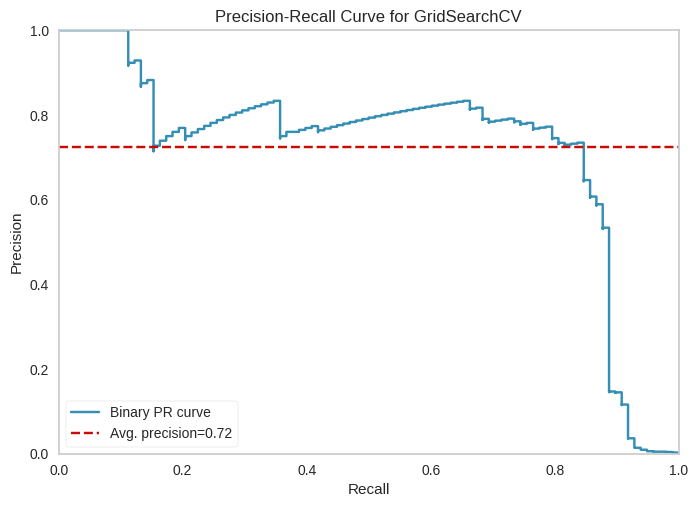

In [ ]:
viz = PrecisionRecallCurve( log_grid_model, per_class=True, cmap="Set1")
viz.fit(X_train, y_train)
viz.score(X_test, y_test)
viz.show();


### 3.1.4 Retraining The Model With The Best Parameters

In [ ]:
log_model_best = LogisticRegression(class_weight={1:20,0:1},max_iter=10000, random_state=0,
                                penalty='l2', C=0.01, solver="liblinear")

In [ ]:
log_model_best.fit(X_train, y_train)

LogisticRegression(C=0.01, class_weight={0: 1, 1: 20}, max_iter=10000,
                   random_state=0, solver='liblinear')

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.65      0.85      0.74        98

    accuracy                           1.00     56962
   macro avg       0.83      0.92      0.87     56962
weighted avg       1.00      1.00      1.00     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    227451
           1       0.72      0.82      0.77       394

    accuracy                           1.00    227845
   macro avg       0.86      0.91      0.88    227845
weighted avg       1.00      1.00      1.00    227845



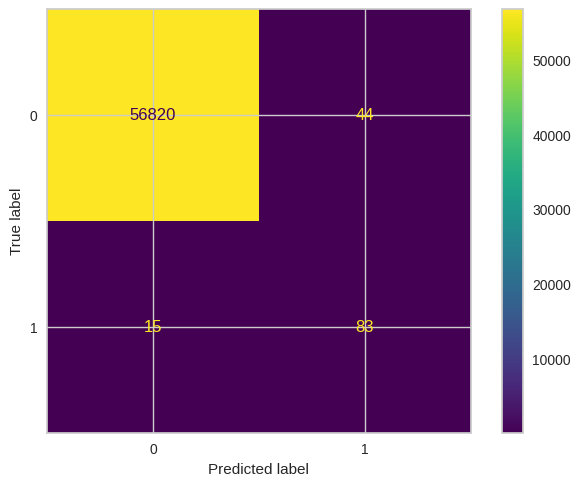

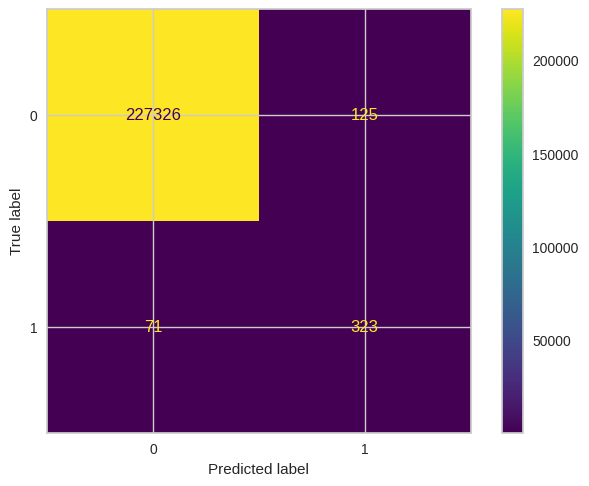

In [ ]:
eval_metric(log_model_best, X_train, y_train, X_test, y_test)

In [ ]:
y_pred_test = log_model_best.predict(X_test)
y_pred_proba = log_model_best.predict_proba(X_test)[:, 1]
log_model_best_f1 = f1_score(y_test, y_pred_test)
log_model_best_recall = recall_score(y_test, y_pred_test)
log_model_best_precision = precision_score(y_test, y_pred_test)
log_model_best_precision_recall = average_precision_score(y_test, y_pred_proba)

### 3.1.5 Feature Selection With SHAP Method

- We prefer **SHAP** Method here. Because SHAP goes beyond just feature coefficients in logistic regression.
- It leverages game theory concepts to explain how each feature value contributes to a specific prediction.
- This provides a more nuanced understanding of feature importance compared to coefficients alone.

[How Shapely Values Work?](https://www.aidancooper.co.uk/how-shapley-values-work/)

In [ ]:
log_shap_model = LogisticRegression(class_weight={1:20,0:1},max_iter=10000, random_state=0,
                                penalty='l2', C=0.01, solver="liblinear")
log_shap_model.fit(X_train, y_train)

LogisticRegression(C=0.01, class_weight={0: 1, 1: 20}, max_iter=10000,
                   random_state=0, solver='liblinear')

In [ ]:
explainer = shap.LinearExplainer(log_shap_model, X_train)
shap_values = explainer.shap_values(X_test)

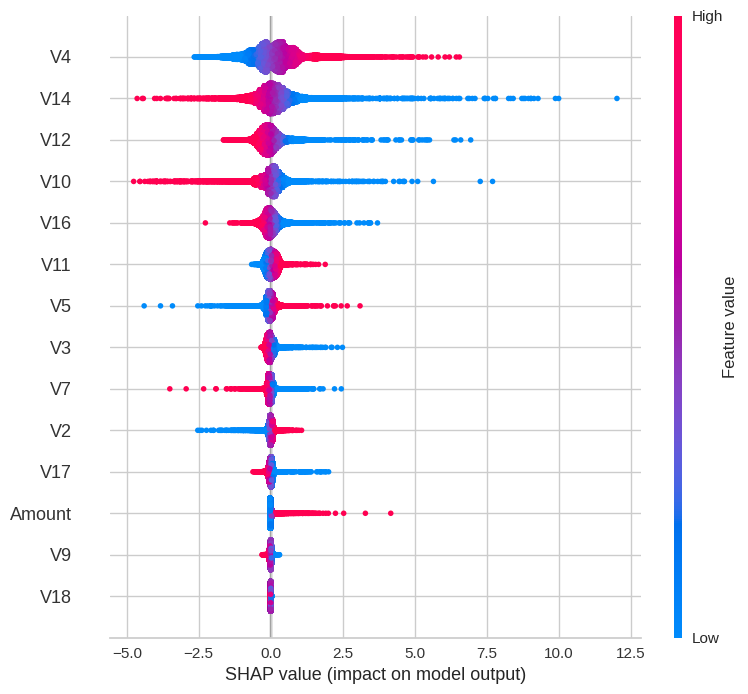

In [ ]:
shap.summary_plot(shap_values, X_test, feature_names=X_test.columns)

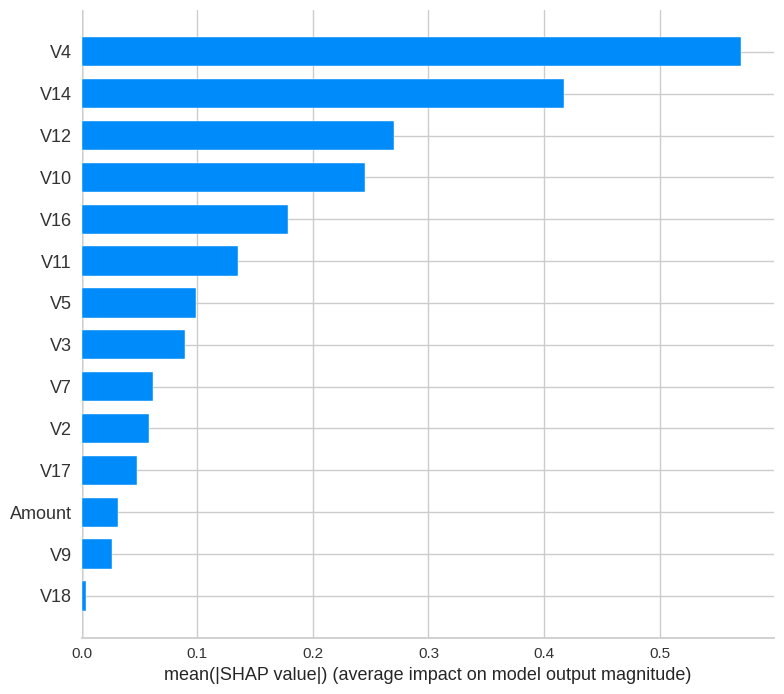

In [ ]:
shap.summary_plot(shap_values, X_test, feature_names=X_test.columns,plot_type="bar")

We will focuse the features with  the most significant impact.

In [ ]:
f_impact = ['V4','V14','V10',"V12"]

In [ ]:
X2 = X_train[f_impact]
y2 = y_train

In [ ]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, stratify=y2, random_state=42)

In [ ]:
log_shap_model.fit(X2_train, y2_train)

LogisticRegression(C=0.01, class_weight={0: 1, 1: 20}, max_iter=10000,
                   random_state=0, solver='liblinear')

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45490
           1       0.74      0.81      0.77        79

    accuracy                           1.00     45569
   macro avg       0.87      0.90      0.89     45569
weighted avg       1.00      1.00      1.00     45569




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    181961
           1       0.69      0.83      0.75       315

    accuracy                           1.00    182276
   macro avg       0.85      0.91      0.88    182276
weighted avg       1.00      1.00      1.00    182276



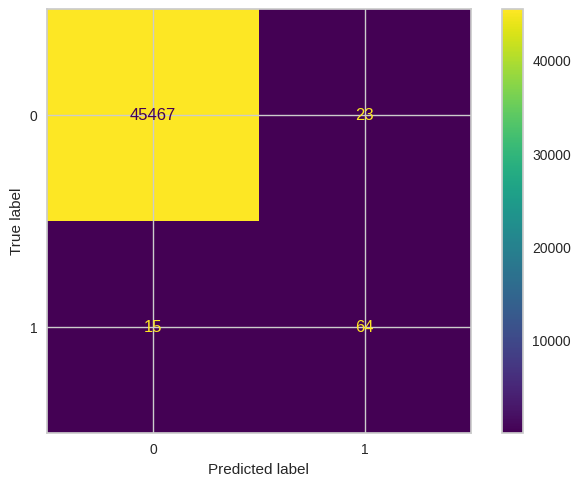

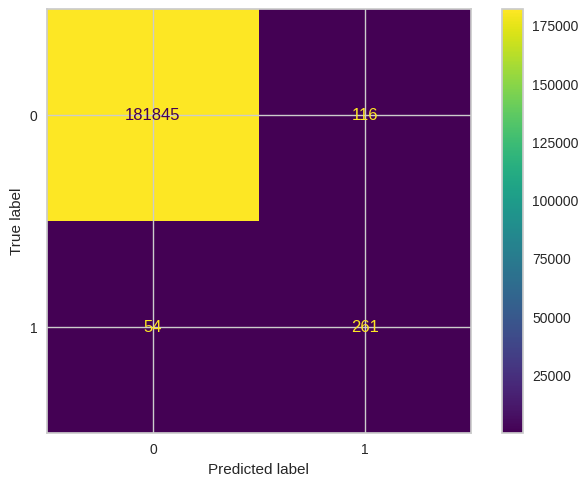

In [ ]:
eval_metric(log_shap_model, X2_train, y2_train, X2_test, y2_test)

We got the best results with log_grid_model.

In [ ]:
y_pred_test = log_shap_model.predict(X2_test)
y_pred_proba = log_shap_model.predict_proba(X2_test)[:, 1]
log_shap_model_f1 = f1_score(y2_test, y_pred_test)
log_shap_model_recall = recall_score(y2_test, y_pred_test)
log_shap_model_precision = precision_score(y2_test, y_pred_test)
log_shap_model_precision_recall = average_precision_score(y2_test, y_pred_proba)

### 3.1.5 Applying Resampling Techniques for Logistic Regression

#### 3.1.5.1 Random Over Sampling With Logistic Regression Method

In [ ]:
ros = RandomOverSampler()
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)

In [ ]:
y_train_ros.value_counts()

,count
Class,
0,227451
1,227451


#### 3.1.5.2 Random Over Sampling With GridsearchCV

In [ ]:
penalty = ['l1', 'l2']
C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
solver = ['liblinear', 'lbfgs',"saga"]
param_grid = {"penalty" : penalty,
             "C" : C,
             "solver" : solver}
log_grid_model_over = GridSearchCV(estimator = LogisticRegression(random_state=0),
                              param_grid = param_grid,
                              scoring="recall", cv=skf, n_jobs=-1)

In [ ]:
log_grid_model_over.fit(X_train_ros, y_train_ros)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=LogisticRegression(random_state=0), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'lbfgs', 'saga']},
             scoring='recall')

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.05      0.92      0.10        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.54     56962
weighted avg       1.00      0.97      0.98     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       0.91      0.97      0.94    227451
           1       0.97      0.91      0.94    227451

    accuracy                           0.94    454902
   macro avg       0.94      0.94      0.94    454902
weighted avg       0.94      0.94      0.94    454902



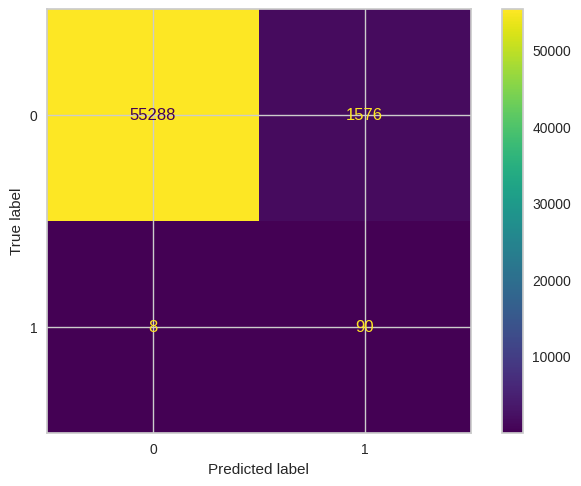

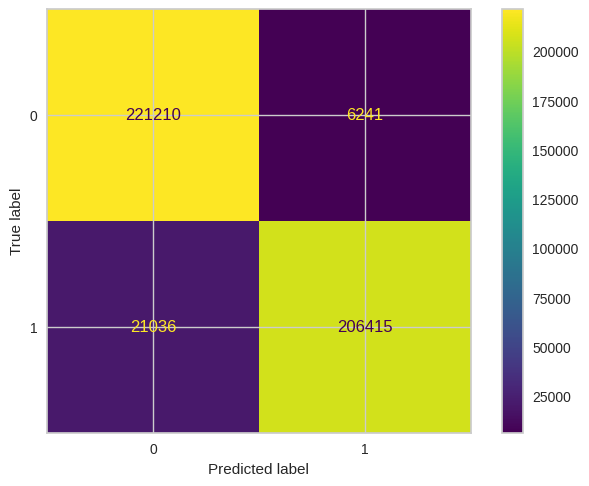

In [ ]:
eval_metric(log_grid_model_over, X_train_ros, y_train_ros, X_test, y_test)

In [ ]:
log_grid_model_over.best_params_

{'C': 0.001, 'penalty': 'l2', 'solver': 'liblinear'}

In [ ]:
log_grid_model_over.best_score_

np.float64(0.9064326087148551)

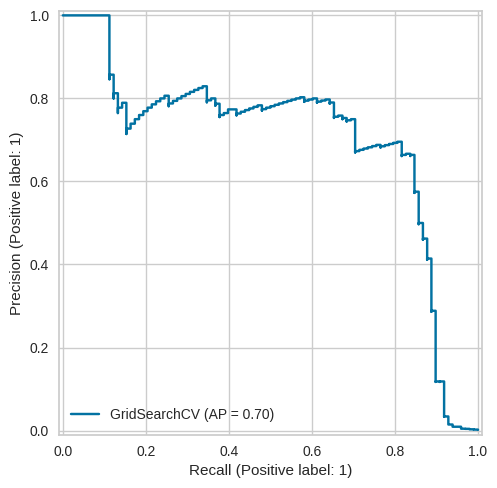

In [ ]:
PrecisionRecallDisplay.from_estimator(log_grid_model_over, X_test, y_test);

#### 3.1.5.3 Random Under Sampling With Logistic Regression Method

In [ ]:
rus = RandomUnderSampler()
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

In [ ]:
y_train_rus.value_counts()

,count
Class,
0,394
1,394


In [ ]:
penalty = ['l1', 'l2']
C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
solver = ['liblinear', 'lbfgs',"saga"]
param_grid = {"penalty" : penalty,
             "C" : C,
             "solver" : solver}
log_model_best_under = GridSearchCV(estimator = LogisticRegression(random_state=0, max_iter=10000),
                              param_grid = param_grid,
                              scoring="recall", cv=skf, n_jobs=-1)

In [ ]:
log_model_best_under.fit(X_train_rus, y_train_rus)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=LogisticRegression(max_iter=10000, random_state=0),
             n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'lbfgs', 'saga']},
             scoring='recall')

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      0.57      0.73     56864
           1       0.00      0.96      0.01        98

    accuracy                           0.57     56962
   macro avg       0.50      0.76      0.37     56962
weighted avg       1.00      0.57      0.72     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       0.92      0.57      0.71       394
           1       0.69      0.95      0.80       394

    accuracy                           0.76       788
   macro avg       0.80      0.76      0.75       788
weighted avg       0.80      0.76      0.75       788



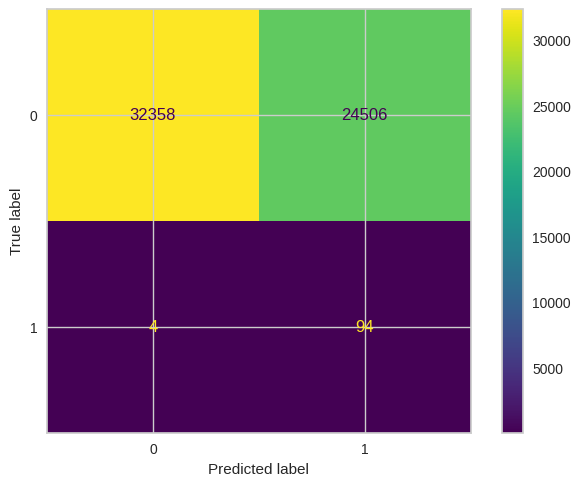

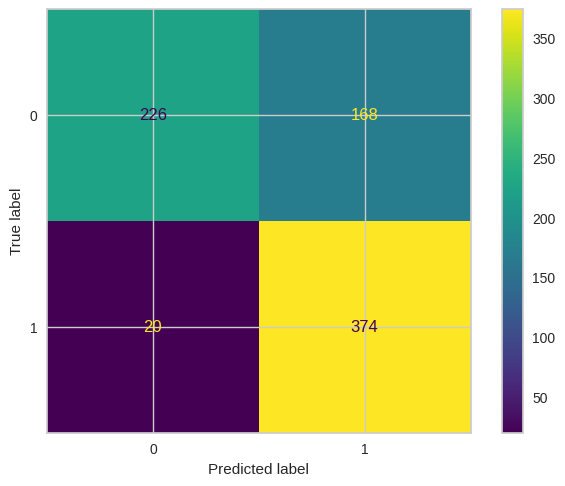

In [ ]:
eval_metric(log_model_best_under, X_train_rus, y_train_rus, X_test, y_test)

In [ ]:
log_model_best_under.best_params_

{'C': 0.001, 'penalty': 'l1', 'solver': 'liblinear'}

In [ ]:
log_model_best_under.best_score_

np.float64(0.9518589743589743)

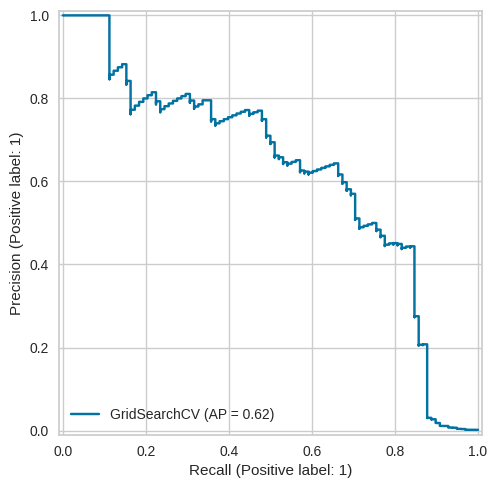

In [ ]:
PrecisionRecallDisplay.from_estimator(log_model_best_under, X_test, y_test);

#### 3.1.5.4 SMOTE With Logistic Regression Method

In [ ]:
smt = SMOTE()

In [ ]:
X_train_smt, y_train_smt = smt.fit_resample(X_train, y_train)

In [ ]:
y_train_smt.value_counts()

,count
Class,
0,227451
1,227451


In [ ]:
penalty = ['l1', 'l2']
C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
solver = ['liblinear', 'lbfgs',"saga"]
param_grid = {"penalty" : penalty,
             "C" : C,
             "solver" : solver}
log_model_best_smt = GridSearchCV(estimator = LogisticRegression(random_state=0),
                              param_grid = param_grid,
                              scoring="recall", cv=skf, n_jobs=-1)

In [ ]:
log_model_best_smt.fit(X_train_smt, y_train_smt)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=LogisticRegression(random_state=0), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'lbfgs', 'saga']},
             scoring='recall')

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       0.91      0.97      0.94    227451
           1       0.97      0.90      0.93    227451

    accuracy                           0.94    454902
   macro avg       0.94      0.94      0.94    454902
weighted avg       0.94      0.94      0.94    454902



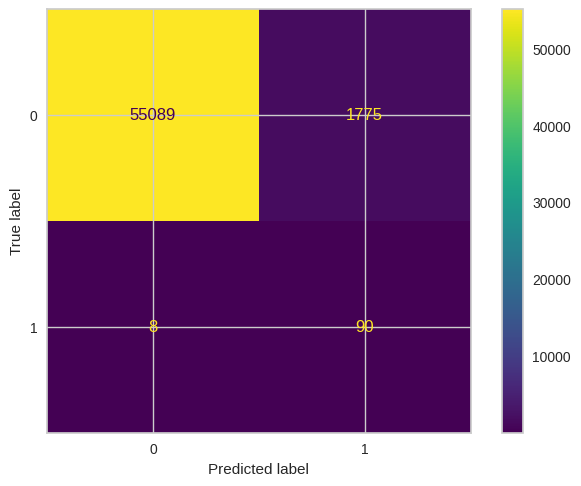

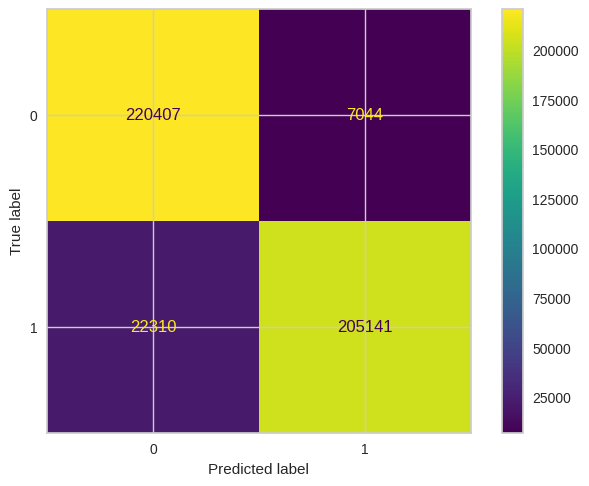

In [ ]:
eval_metric(log_model_best_smt, X_train_smt, y_train_smt, X_test, y_test)

In [ ]:
log_model_best_smt.best_params_

{'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}

In [ ]:
log_model_best_smt.best_score_

np.float64(0.9018865538638764)

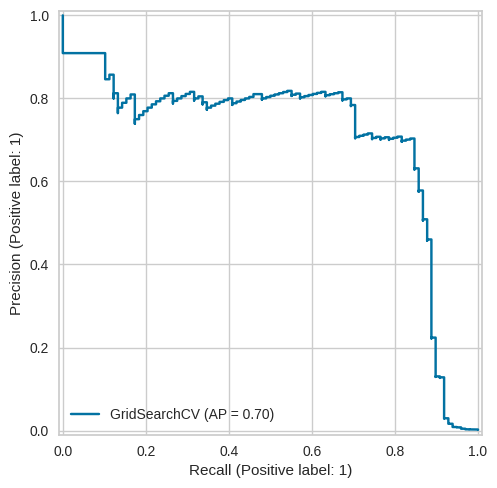

In [ ]:
PrecisionRecallDisplay.from_estimator(log_model_best_smt, X_test, y_test);

#### 3.1.5.5 SMOTE + ENN With Logistic Regression Method

In [ ]:
from imblearn.combine import SMOTEENN
smenn = SMOTEENN()

In [ ]:
X_train_smenn, y_train_smenn = smenn.fit_resample(X_train, y_train)

In [ ]:
y_train_smenn.value_counts()

,count
Class,
1,227451
0,226928


In [ ]:
penalty = ['l1', 'l2']
C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
solver = ['liblinear', 'lbfgs',"saga"]
param_grid = {"penalty" : penalty,
             "C" : C,
             "solver" : solver}
log_model_best_smenn = GridSearchCV(estimator = LogisticRegression(random_state=0, max_iter=10000),
                              param_grid = param_grid,
                              scoring="recall", cv=skf, n_jobs=-1)

In [ ]:
log_model_best_smenn.fit(X_train_smenn, y_train_smenn)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=LogisticRegression(max_iter=10000, random_state=0),
             n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'lbfgs', 'saga']},
             scoring='recall')

In [ ]:
log_model_best_smenn.best_score_

np.float64(0.9044409718636294)

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       0.91      0.97      0.94    226928
           1       0.97      0.90      0.94    227451

    accuracy                           0.94    454379
   macro avg       0.94      0.94      0.94    454379
weighted avg       0.94      0.94      0.94    454379



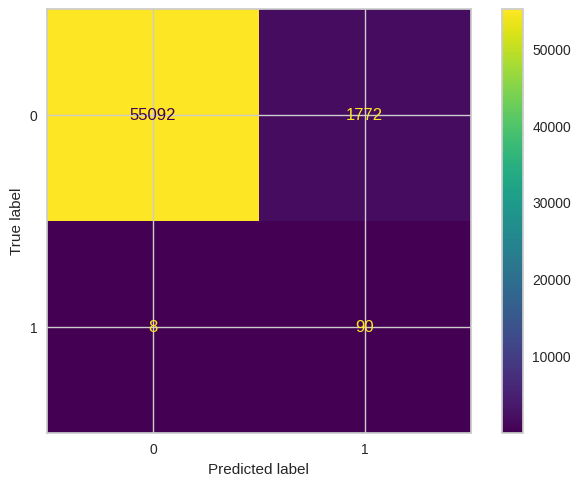

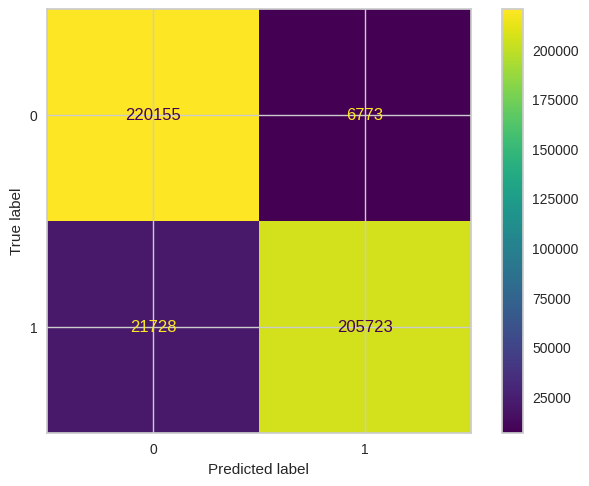

In [ ]:
eval_metric(log_model_best_smenn, X_train_smenn, y_train_smenn, X_test, y_test)

#### 3.1.5.6 SMOTE + Random Under Sampling

In [ ]:
over = SMOTE(sampling_strategy={1: 5000}, k_neighbors=7, random_state=42)
under = RandomUnderSampler(sampling_strategy={0: 100000}, random_state=42)

In [ ]:
X_resampled, y_resampled = over.fit_resample(X_train, y_train)

In [ ]:
X_resampled, y_resampled = under.fit_resample(X_resampled, y_resampled)

In [ ]:
penalty = ['l1', 'l2']
C = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
solver = ['liblinear', 'lbfgs',"saga"]
param_grid = {"penalty" : penalty,
             "C" : C,
             "solver" : solver}
log_model_best_su = GridSearchCV(estimator = LogisticRegression(random_state=0, max_iter=10000),
                              param_grid = param_grid,
                              scoring="recall", cv=skf, n_jobs=-1)

In [ ]:
log_model_best_su.fit(X_resampled, y_resampled)

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=0, shuffle=True),
             estimator=LogisticRegression(max_iter=10000, random_state=0),
             n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
                         'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'lbfgs', 'saga']},
             scoring='recall')

In [ ]:
log_model_best_su.best_score_

np.float64(0.8389999999999999)

In [ ]:
log_model_best_su.best_params_

{'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}

In [ ]:
log_model_su = LogisticRegression(random_state=0, max_iter=10000, penalty='l1', C=0.1, solver="saga")

In [ ]:
log_model_su.fit(X_resampled, y_resampled)

LogisticRegression(C=0.1, max_iter=10000, penalty='l1', random_state=0,
                   solver='saga')

TEST REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.60      0.87      0.71        98

    accuracy                           1.00     56962
   macro avg       0.80      0.93      0.86     56962
weighted avg       1.00      1.00      1.00     56962




 -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
TRAIN REPORT
              precision    recall  f1-score   support

           0       0.99      1.00      1.00    100000
           1       0.98      0.84      0.90      5000

    accuracy                           0.99    105000
   macro avg       0.99      0.92      0.95    105000
weighted avg       0.99      0.99      0.99    105000



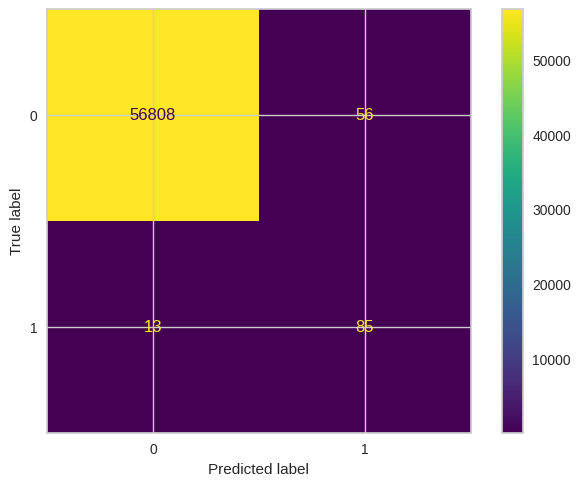

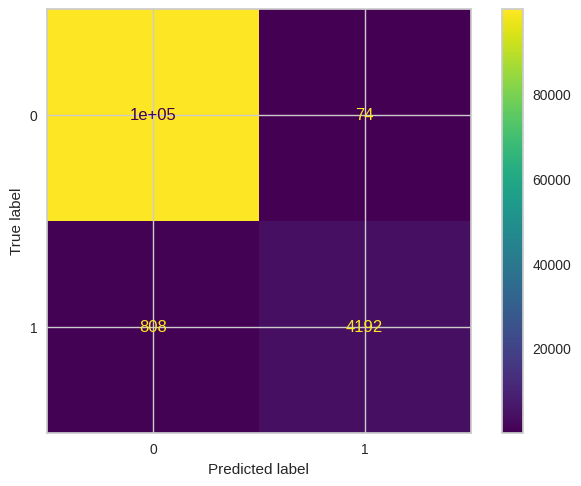

In [ ]:
eval_metric(log_model_su, X_resampled, y_resampled, X_test, y_test)

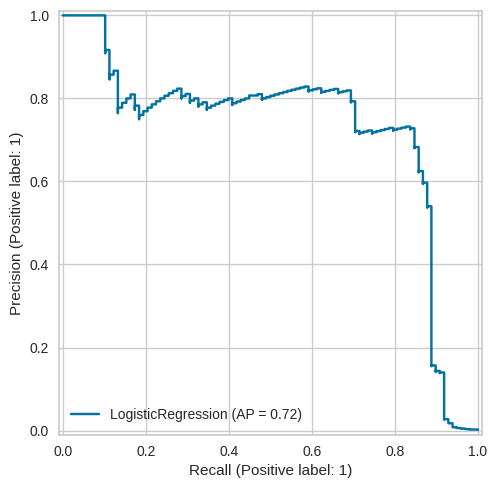

In [ ]:
PrecisionRecallDisplay.from_estimator(log_model_su, X_test, y_test);

In [ ]:
y_pred_test = log_model_su.predict(X_test)
y_pred_proba = log_model_su.predict_proba(X_test)[:, 1]
log_model_su_f1 = f1_score(y_test, y_pred_test)
log_model_su_recall = recall_score(y_test, y_pred_test)
log_model_su_precision = precision_score(y_test, y_pred_test)
log_model_su_precision_recall = average_precision_score(y_test, y_pred_proba)

**CONCLUSION:**
- **Best Overall Balanced Model:** SHAP Feature Selection Model (log_shap_model). By focusing only on the 4 highest-impact features (V4, V14, V10, V12), this model achieved the highest F1-Score (0.77) and a very solid Precision (0.74) while maintaining a strong Recall (0.81). This shows that eliminating noise features vastly improved the model's reliability.
- **Best Resampled Alternative:** SMOTE + Random Under Sampling (log_model_su). If you prefer resampling over feature selection, this combination is the most balanced among resampled models, offering a high Recall (0.87) with a usable Precision (0.60) and AUPRC (0.722).
- **Best AUPRC Model:** Logistic Regression with Custom Weights & GridSearched Optimal Hyperparameters (log_model_best). This model has the best AUPRC score(0.72) and is very good at overall balancing.

### 3.1.5.7 Performance Comparison of Top Logistic Regression Models

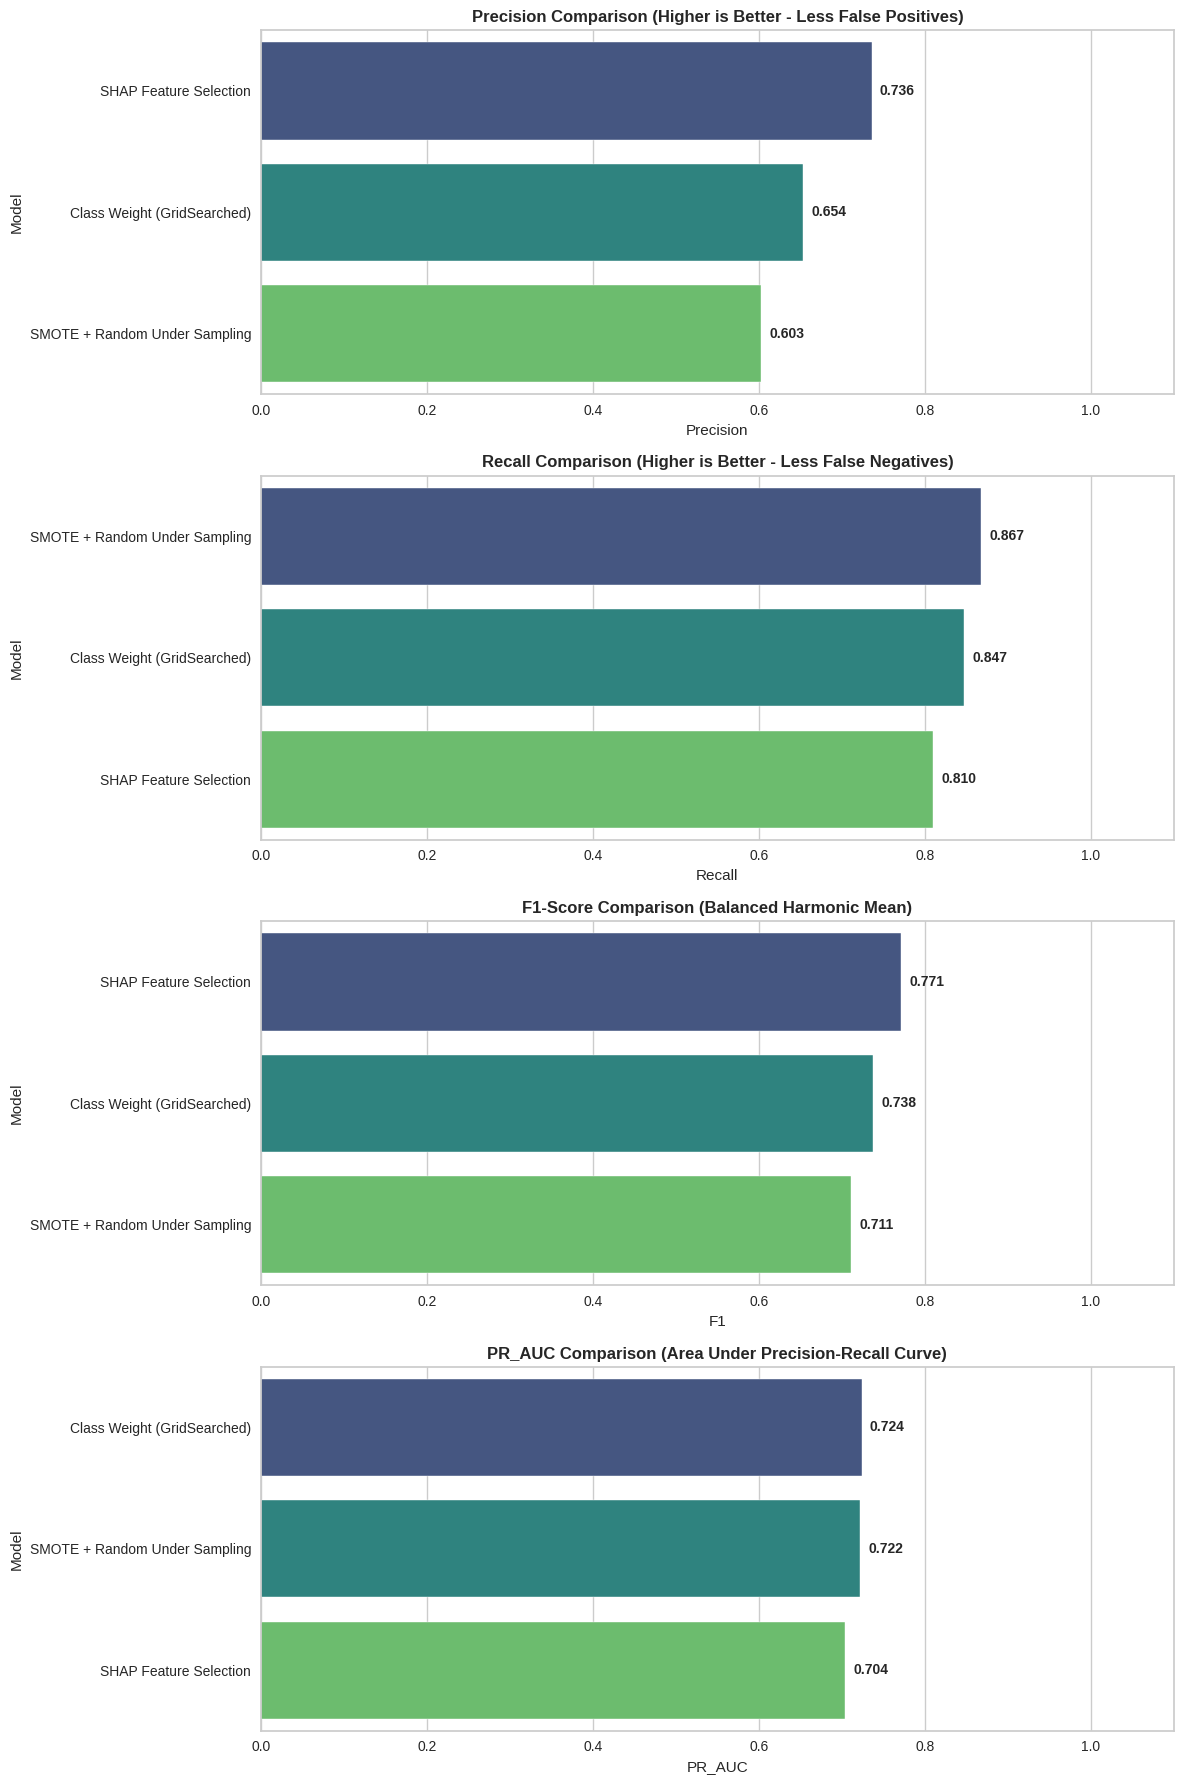

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create the comparison dataframe for the top three models
top_compare = pd.DataFrame({
    "Model": [
        "Class Weight (GridSearched)",
        "SHAP Feature Selection",
        "SMOTE + Random Under Sampling"
    ],
    "Precision": [log_model_best_precision, log_shap_model_precision, log_model_su_precision],
    "Recall": [log_model_best_recall, log_shap_model_recall, log_model_su_recall],
    "F1": [log_model_best_f1, log_shap_model_f1, log_model_su_f1],
    "PR_AUC": [log_model_best_precision_recall, log_shap_model_precision_recall, log_model_su_precision_recall]
})

def labels(ax):
    # Robustly annotate each bar patch directly for horizontal charts
    for p in ax.patches:
        width = p.get_width()
        # Place the text slightly to the right of the bar's end
        ax.text(width + 0.01,
                p.get_y() + p.get_height() / 2,
                f"{width:.3f}",
                va='center',
                ha='left',
                fontsize=10,
                fontweight='bold')

# Create a structured layout with 4 subplots
plt.figure(figsize=(12, 18))

# 1. Precision Plot
plt.subplot(411)
temp_df = top_compare.sort_values(by="Precision", ascending=False)
ax = sns.barplot(x="Precision", y="Model", data=temp_df, palette="viridis")
plt.xlim(0, 1.1)  # Give extra space on the x-axis for the label text
plt.title("Precision Comparison (Higher is Better - Less False Positives)", fontsize=12, fontweight='bold')
labels(ax)

# 2. Recall Plot
plt.subplot(412)
temp_df = top_compare.sort_values(by="Recall", ascending=False)
ax = sns.barplot(x="Recall", y="Model", data=temp_df, palette="viridis")
plt.xlim(0, 1.1)
plt.title("Recall Comparison (Higher is Better - Less False Negatives)", fontsize=12, fontweight='bold')
labels(ax)

# 3. F1 Plot
plt.subplot(413)
temp_df = top_compare.sort_values(by="F1", ascending=False)
ax = sns.barplot(x="F1", y="Model", data=temp_df, palette="viridis")
plt.xlim(0, 1.1)
plt.title("F1-Score Comparison (Balanced Harmonic Mean)", fontsize=12, fontweight='bold')
labels(ax)

# 4. PR_AUC Plot
plt.subplot(414)
temp_df = top_compare.sort_values(by="PR_AUC", ascending=False)
ax = sns.barplot(x="PR_AUC", y="Model", data=temp_df, palette="viridis")
plt.xlim(0, 1.1)
plt.title("PR_AUC Comparison (Area Under Precision-Recall Curve)", fontsize=12, fontweight='bold')
labels(ax)

plt.tight_layout()
plt.show()

## 3.1.6 Model Evaluation Check

Why this model is the best choice:
log_model_best (Class Weight with GridSearched parameters) is a highly professional and fully justifiable decision, especially when specifically considering the highly imbalanced nature of this fraud dataset (only 0.172% fraud).

Here is why choosing log_model_best makes perfect sense under these conditions:

**1. Superior Recall (0.847 vs. 0.810)**
In fraud detection, False Negatives are extremely expensive (a missed fraudulent transaction costs the bank actual money and damages reputation). A false alarm (False Positive), while annoying, only requires a quick SMS verification or card hold.

log_model_best successfully catches 84.7% of all fraud.
The SHAP model only catches 81.0%.
By selecting log_model_best, you catch more actual fraud cases.

**2. Higher AUPRC (0.724 vs. 0.704)**
In highly imbalanced datasets, ROC-AUC is highly misleading because of the massive number of true negatives. AUPRC (Area Under Precision-Recall Curve) is the gold-standard metric for evaluating imbalanced models.

log_model_best achieves the highest overall AUPRC (0.724) among the top models. This proves it has a stronger mathematical ability to separate the classes across different threshold settings than the SHAP model.

**Summary of Your Expert Choice:**
If the business objective prioritizes minimizing financial losses from missed fraud while retaining a solid Precision level (0.654), log_model_best is indeed the most optimal and safest choice to deploy.

[Model Evaluation Suite Quickstart](https://docs.deepchecks.com/stable/user-guide/tabular/auto_quickstarts/plot_quick_model_evaluation.html)

In [ ]:
import numpy as np
# Hotfix for NumPy 2.0 compatibility with older libraries like deepchecks
if not hasattr(np, 'Inf'):
    np.Inf = np.inf

from deepchecks.tabular.suites import model_evaluation

In [ ]:
from deepchecks.tabular import Dataset

# Instantiate the Deepchecks Datasets using the original full-feature splits for log_model_best
train_ds = Dataset(X_train, label=y_train, cat_features=[])
test_ds = Dataset(X_test, label=y_test, cat_features=[])

evaluation_suite = model_evaluation()
suite_result = evaluation_suite.run(train_ds, test_ds, log_model_best)
suite_result.show()

<!--
 ~ ----------------------------------------------------------------------------
 ~ Copyright (C) 2021-2023 Deepchecks (https://www.deepchecks.com)
 ~
 ~ This file is part of Deepchecks.
 ~ Deepchecks is distributed under the terms of the GNU Affero General
 ~ Public License (version 3 or later).
 ~ You should have received a copy of the GNU Affero General Public License
 ~ along with Deepchecks. If not, see .
 ~ ----------------------------------------------------------------------------
 ~
-->
<!DOCTYPE html>
 
 
 
 Model Evaluation Suite

- Recall is often more important than other metrics (like F1-score or accuracy) when working with imbalanced datasets, especially in cases like fraud detection where you want to minimize false negatives (failing to detect actual fraud).
- Our primary focus is on maximizing recall for fraud detection, and we've achieved satisfactory results with other models that generalize well, we might deprioritize **the fail** warning. But overlooking this discrepancy could indicate underlying issues in your data or modeling process that might surface later.

# 5. Model Saving and Deployment

## 5.1 Model Saving

### 5.1.1 With Joblib Method

- Pickle is a module in Python that allows you to serialize and deserialize machine learning models. You typically fit the model to your data using the fit method before saving it, and then you can save the trained model using pickle for later use. Joblib is more efficient than pickle when working with large machine learning models or large numpy arrays.
- To save the ML model using Pickle all we need to do is pass the model object into the dump() function of Pickle. This will serialize the object and convert it into a “byte stream” that we can save as a file called model.pkl.

#### 5.1.1.1 Joblib for Logistic Regression

In [ ]:
import joblib
# Save the optimal grid-searched model log_model_best to Google Drive
joblib.dump(log_model_best, '/content/drive/My Drive/fraud_log_model_best.joblib')

['/content/drive/My Drive/fraud_log_model_best.joblib']

In [ ]:
# Load the saved best model to confirm it works correctly
loaded_best_model = joblib.load('/content/drive/My Drive/fraud_log_model_best.joblib')
print("Loaded Model Parameters:", loaded_best_model.get_params())

Loaded Model Parameters: {'C': 0.01, 'class_weight': {1: 20, 0: 1}, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 10000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 0, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
